# RetailIQ Business EDA and Cohort Retention

## tl;dr

Customer value is concentrated: the top 20% of known purchasing customers generated 77.2% of customer revenue. Cohorts are evaluated by months since first purchase so recent cohorts are not mistaken for weak mature cohorts.

## Context & Methods

This analysis explains revenue, customer concentration, and repeat purchasing from cleaned tables. It is descriptive and does not claim causal effects.

### Key Assumptions

Revenue is reported in the source currency. Cancellations reduce net revenue only when a positive source price is available.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

## Data

### 1. Load analytical tables

In [2]:
transactions = pd.read_parquet(ROOT / 'data/processed/transactions.parquet')
orders = pd.read_parquet(ROOT / 'data/processed/orders.parquet')
customers = pd.read_parquet(ROOT / 'data/processed/customers.parquet')
weekly = pd.read_parquet(ROOT / 'data/processed/weekly_revenue.parquet')

## Results

### 2. Executive metrics

In [3]:
sales_orders = orders.loc[orders['gross_revenue'].gt(0)]
metrics = pd.Series({
 'Net revenue': transactions['net_line_revenue'].sum(),
 'Gross revenue': transactions['gross_line_revenue'].sum(),
 'Returned value': transactions['returned_value'].sum(),
 'Sales orders': sales_orders['invoice'].nunique(),
 'Known purchasing customers': customers['customer_id'].nunique(),
 'Average sales order value': sales_orders['gross_revenue'].mean(),
})
display(metrics.to_frame('value'))

,value
Net revenue,"19,340,764.47"
Gross revenue,"20,064,123.05"
Returned value,"723,358.58"
Sales orders,"39,517.00"
Known purchasing customers,"5,852.00"
Average sales order value,506.68


### 3. Weekly revenue story

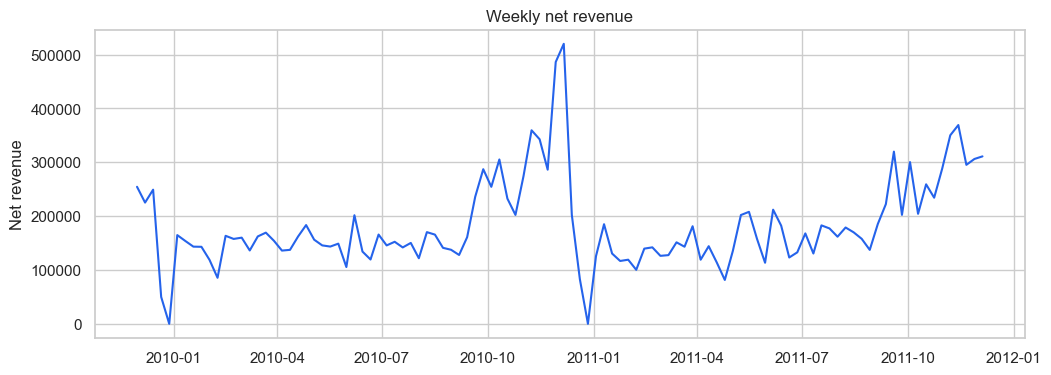

In [4]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(weekly['invoice_week'], weekly['net_revenue'], color='#2563EB')
ax.set(title='Weekly net revenue', xlabel='', ylabel='Net revenue')
plt.show()

### 4. Customer concentration

In [5]:
ranked = customers.sort_values('gross_revenue', ascending=False).copy()
ranked['cumulative_share'] = ranked['gross_revenue'].cumsum() / ranked['gross_revenue'].sum()
top_20_count = max(1, int(np.ceil(len(ranked) * .20)))
print(f"Top 20% customer revenue share: {ranked.head(top_20_count)['gross_revenue'].sum()/ranked['gross_revenue'].sum():.1%}")

Top 20% customer revenue share: 77.2%


### 5. Which countries contribute most to net revenue?

,gross_revenue,returned_value,net_revenue,customers,net_revenue_share
country,,,,,
United Kingdom,"17,189,624.59","638,744.45","16,550,880.14",5410,0.86
EIRE,"628,546.94","20,305.05","608,241.89",5,0.03
Netherlands,"549,951.01","3,677.98","546,273.03",23,0.03
Germany,"388,271.08","8,928.84","379,342.24",107,0.02
France,"316,750.71","17,686.24","299,064.47",95,0.02
Australia,"168,417.16","1,517.86","166,899.30",15,0.01
Switzerland,"94,247.99","1,106.53","93,141.46",22,0.00
Spain,"98,561.47","12,955.19","85,606.28",41,0.00
Sweden,"86,319.14","1,973.97","84,345.17",19,0.00


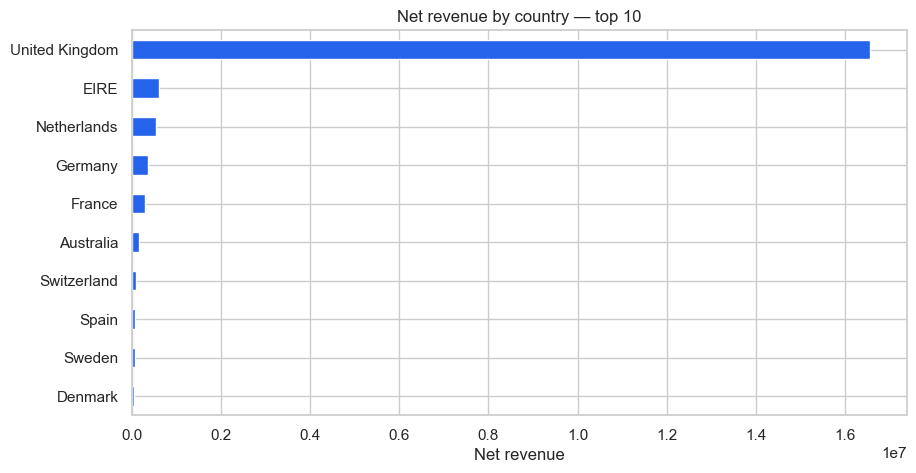

United Kingdom share of net revenue: 85.6%


In [6]:
country = transactions.groupby('country').agg(
 gross_revenue=('gross_line_revenue','sum'), returned_value=('returned_value','sum'),
 net_revenue=('net_line_revenue','sum'), customers=('customer_id','nunique')
).sort_values('net_revenue', ascending=False)
country['net_revenue_share'] = country['net_revenue'] / country['net_revenue'].sum()
display(country.head(10))
fig, ax = plt.subplots(figsize=(10,5))
country.head(10).sort_values('net_revenue')['net_revenue'].plot.barh(ax=ax, color='#2563EB')
ax.set(title='Net revenue by country — top 10', xlabel='Net revenue', ylabel='')
plt.show()
print(f"United Kingdom share of net revenue: {country.loc['United Kingdom','net_revenue_share']:.1%}")

### 6. Which products generate revenue, and which lose value to cancellations?

,stock_code,description,net_revenue,invoices
3113,22423,REGENCY CAKESTAND 3 TIER,"327,345.20",4261
7861,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,192.70",5594
7813,85099B,JUMBO BAG RED RETROSPOT,"148,505.35",3344
5654,47566,PARTY BUNTING,"147,870.80",2699
7309,84879,ASSORTED COLOUR BIRD ORNAMENT,"131,043.74",2827
2572,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"121,523.49",2034
6268,79321,CHILLI LIGHTS,"84,521.81",1161
6586,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"73,745.87",762
1121,21137,BLACK RECORD COVER FRAME,"69,213.43",641
7818,85099F,JUMBO BAG STRAWBERRY,"68,947.57",1884


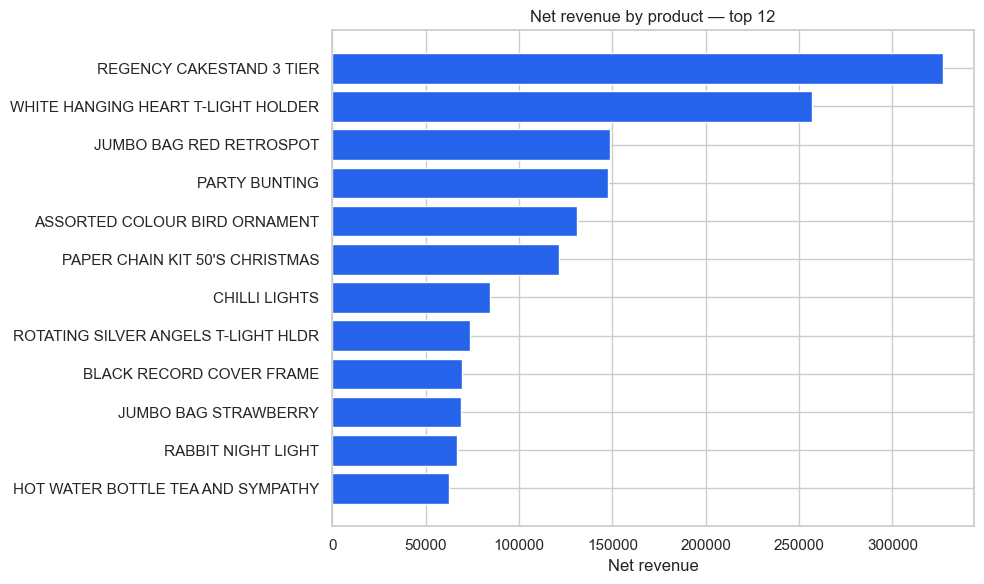

,stock_code,description,gross_revenue,returned_value,return_value_rate
4915,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60","168,469.60",0.50
4328,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92","77,479.64",0.49
3113,22423,REGENCY CAKESTAND 3 TIER,"344,069.30","16,724.10",0.05
7861,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"266,582.35","9,389.65",0.03
5856,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,"42,938.17","6,976.41",0.14
1070,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"25,859.05","6,614.37",0.20
6290,79323W,WHITE CHERRY LIGHTS,"18,048.72","6,421.10",0.26
6476,84078A,SET/4 WHITE RETRO STORAGE CUBES,"43,921.51","5,187.65",0.11
4249,23113,PANTRY CHOPPING BOARD,"5,868.50","4,803.06",0.45
5768,48185,DOORMAT FAIRY CAKE,"34,518.68","4,650.20",0.12


In [7]:
product = transactions.groupby(['stock_code','description'], dropna=False).agg(
 gross_revenue=('gross_line_revenue','sum'), returned_value=('returned_value','sum'),
 net_revenue=('net_line_revenue','sum'), invoices=('invoice','nunique')
).reset_index()
product['return_value_rate'] = product['returned_value'] / (product['gross_revenue'] + product['returned_value']).replace(0,np.nan)
top_products = product.nlargest(12, 'net_revenue')
display(top_products[['stock_code','description','net_revenue','invoices']])
fig, ax = plt.subplots(figsize=(10,6))
plot_data = top_products.sort_values('net_revenue')
ax.barh(plot_data['description'].fillna(plot_data['stock_code']).str[:38], plot_data['net_revenue'], color='#2563EB')
ax.set(title='Net revenue by product — top 12', xlabel='Net revenue', ylabel='')
plt.tight_layout(); plt.show()
return_watch = product.loc[product['gross_revenue'].ge(1000)].nlargest(10,'returned_value')
display(return_watch[['stock_code','description','gross_revenue','returned_value','return_value_rate']])

### 7. Is revenue coming from new or returning customers?

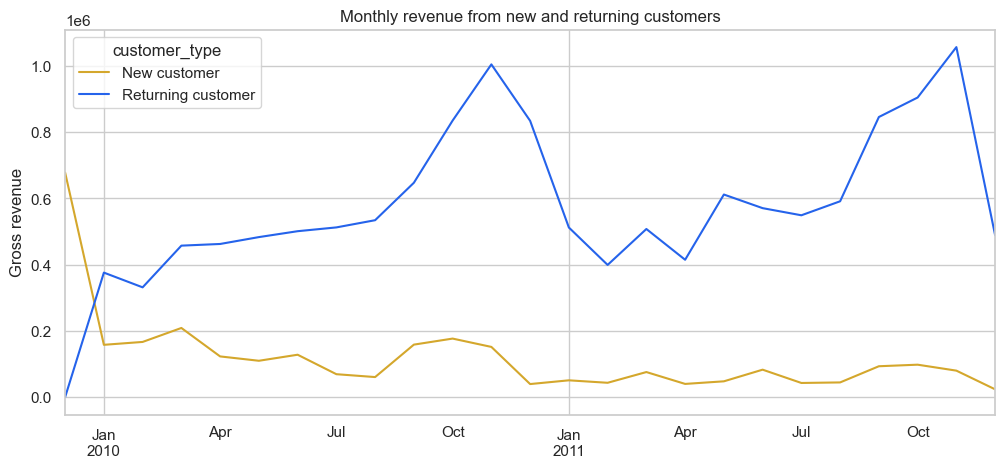

customer_type,New customer,Returning customer
order_month,,
2011-07-01,0.07,0.93
2011-08-01,0.07,0.93
2011-09-01,0.10,0.90
2011-10-01,0.10,0.90
2011-11-01,0.07,0.93
2011-12-01,0.05,0.95


In [8]:
known_orders = sales_orders.loc[sales_orders['customer_id'].notna()].copy()
known_orders['order_month'] = known_orders['invoice_date'].dt.to_period('M').dt.to_timestamp()
first_month = known_orders.groupby('customer_id')['order_month'].min().rename('first_month')
known_orders = known_orders.join(first_month, on='customer_id')
known_orders['customer_type'] = np.where(known_orders['order_month'].eq(known_orders['first_month']), 'New customer', 'Returning customer')
customer_mix = known_orders.groupby(['order_month','customer_type'])['gross_revenue'].sum().unstack(fill_value=0)
customer_mix.plot(figsize=(12,5), color=['#D4A72C','#2563EB'])
plt.title('Monthly revenue from new and returning customers'); plt.xlabel(''); plt.ylabel('Gross revenue'); plt.show()
mix_share = customer_mix.div(customer_mix.sum(axis=1), axis=0)
display(mix_share.tail(6))

### 8. What does a typical order look like?

,gross_revenue,units,distinct_products
count,"39,599.00","39,599.00","39,599.00"
mean,506.68,287.08,25.05
std,"1,486.12","1,206.55",42.17
min,0.19,1.00,1.00
50%,302.45,150.00,15.00
75%,494.13,293.00,28.00
90%,920.11,528.00,51.00
95%,"1,445.33",802.10,72.00
99%,"4,174.65","2,299.02",196.00
max,"168,469.60","87,167.00","1,107.00"


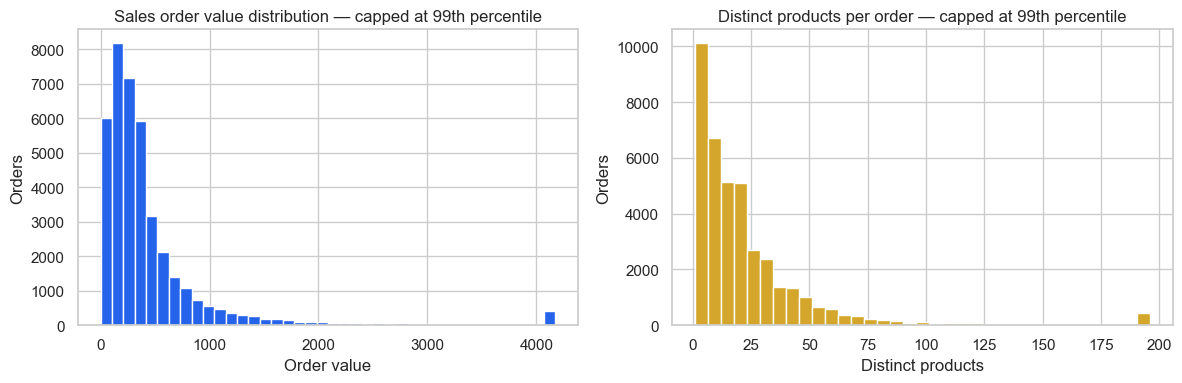

In [9]:
order_profile = sales_orders[['gross_revenue','units','distinct_products']].describe(percentiles=[.5,.75,.9,.95,.99])
display(order_profile)
fig, axes = plt.subplots(1,2,figsize=(12,4))
sales_orders['gross_revenue'].clip(upper=sales_orders['gross_revenue'].quantile(.99)).hist(bins=40, ax=axes[0], color='#2563EB')
axes[0].set(title='Sales order value distribution — capped at 99th percentile', xlabel='Order value', ylabel='Orders')
sales_orders['distinct_products'].clip(upper=sales_orders['distinct_products'].quantile(.99)).hist(bins=35, ax=axes[1], color='#D4A72C')
axes[1].set(title='Distinct products per order — capped at 99th percentile', xlabel='Distinct products', ylabel='Orders')
plt.tight_layout(); plt.show()

### 9. How long do customers wait between purchases?

In [10]:
purchase_dates = known_orders[['customer_id','invoice','invoice_date']].drop_duplicates().sort_values(['customer_id','invoice_date'])
purchase_dates['days_since_previous_order'] = purchase_dates.groupby('customer_id')['invoice_date'].diff().dt.total_seconds().div(86400)
gaps = purchase_dates['days_since_previous_order'].dropna()
display(gaps.describe(percentiles=[.25,.5,.75,.9,.95]).to_frame('days'))
print(f'Median repeat-purchase gap: {gaps.median():.0f} days')

,days
count,"30,806.00"
mean,52.01
std,75.86
min,0.00
25%,7.01
50%,24.97
75%,62.02
90%,135.87
95%,207.01
max,714.15


Median repeat-purchase gap: 25 days


### 10. When does purchasing activity occur?

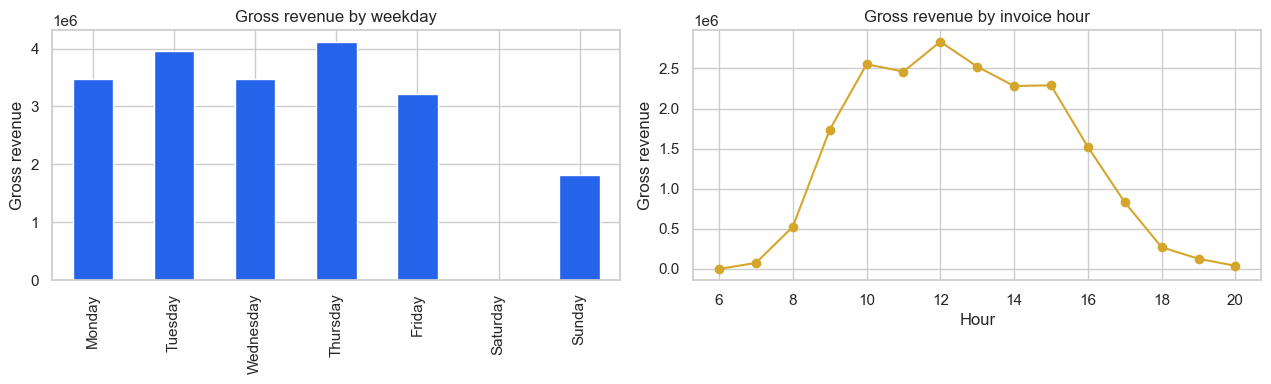

In [11]:
sales_lines = transactions.loc[transactions['transaction_status'].eq('valid_sale')].copy()
sales_lines['weekday'] = sales_lines['invoice_date'].dt.day_name()
sales_lines['hour'] = sales_lines['invoice_date'].dt.hour
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday = sales_lines.groupby('weekday')['gross_line_revenue'].sum().reindex(weekday_order).fillna(0)
hourly = sales_lines.groupby('hour')['gross_line_revenue'].sum()
fig, axes = plt.subplots(1,2,figsize=(13,4))
weekday.plot.bar(ax=axes[0], color='#2563EB'); axes[0].set(title='Gross revenue by weekday', xlabel='', ylabel='Gross revenue')
hourly.plot(ax=axes[1], color='#D4A72C', marker='o'); axes[1].set(title='Gross revenue by invoice hour', xlabel='Hour', ylabel='Gross revenue')
plt.tight_layout(); plt.show()

### 11. What changed in the latest complete month?

In [12]:
monthly_orders = sales_orders.copy()
monthly_orders['month'] = monthly_orders['invoice_date'].dt.to_period('M').dt.to_timestamp()
monthly_kpis = monthly_orders.groupby('month').agg(
 revenue=('gross_revenue','sum'), orders=('invoice','nunique'), active_customers=('customer_id','nunique')
)
monthly_kpis['average_order_value'] = monthly_kpis['revenue'] / monthly_kpis['orders']
complete = monthly_kpis.iloc[1:-1].tail(2)
change = complete.pct_change().iloc[-1].rename('change_vs_previous_month')
display(complete)
display(change.to_frame())
driver = change.abs().sort_values(ascending=False).index[0]
direction = 'increased' if change['revenue'] >= 0 else 'decreased'
print(f"Gross revenue {direction} {abs(change['revenue']):.1%} in {complete.index[-1]:%B %Y}. The largest accompanying KPI movement was {driver.replace('_',' ')} at {change[driver]:+.1%}.")

,revenue,orders,active_customers,average_order_value
month,,,,
2011-10-01,"1,103,327.63",2005,1361,550.29
2011-11-01,"1,452,112.69",2751,1660,527.85


,change_vs_previous_month
revenue,0.32
orders,0.37
active_customers,0.22
average_order_value,-0.04


Gross revenue increased 31.6% in November 2011. The largest accompanying KPI movement was orders at +37.2%.


### 12. Monthly acquisition cohorts

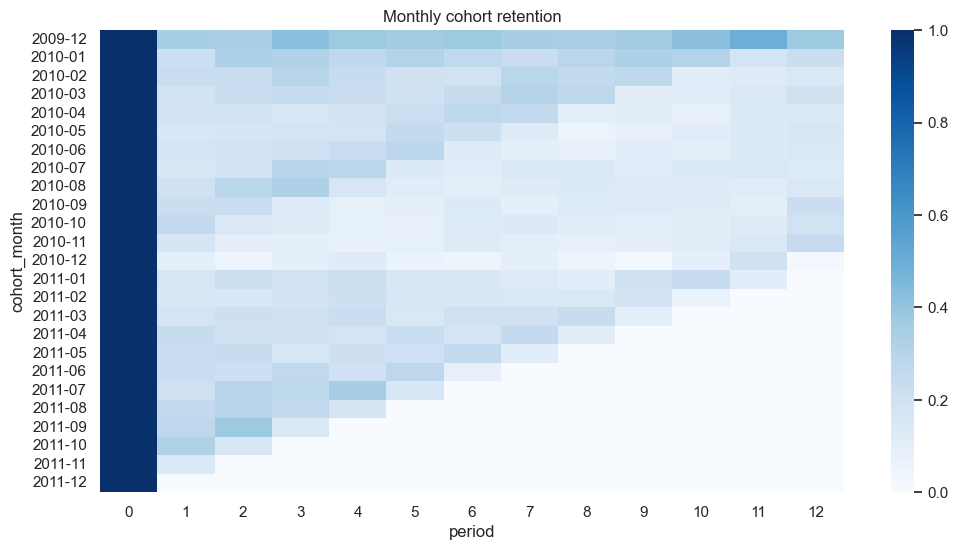

In [13]:
sales = transactions.loc[transactions['eligible_customer_model'] & transactions['transaction_status'].eq('valid_sale')].copy()
sales['order_month'] = sales['invoice_date'].dt.to_period('M')
first_month = sales.groupby('customer_id')['order_month'].min().rename('cohort_month')
cohort = sales[['customer_id','order_month']].drop_duplicates().join(first_month, on='customer_id')
cohort['period'] = (cohort['order_month'].astype(int) - cohort['cohort_month'].astype(int))
counts = cohort.groupby(['cohort_month','period'])['customer_id'].nunique().unstack(fill_value=0)
retention = counts.div(counts[0], axis=0)
fig, ax = plt.subplots(figsize=(12,6))
sns.heatmap(retention.iloc[:, :13], cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Monthly cohort retention')
plt.show()

## Takeaways

The analysis separates revenue level, customer mix, concentration, basket behaviour, cancellation exposure, and retention. Country and product rankings are descriptive; campaign or assortment decisions require margin and experimental evidence that this dataset does not contain.